# Workshop: Gradient Descent in Single- and Multi-Layer Neural Networks

**Course:** Foundations of Machine Learning  
**Audience:** Entry-level students  
**Theme:** Understanding gradient descent mathematically, algorithmically, and through practice in **PyTorch**, followed by implementation challenges in **TensorFlow** and **Keras**.

## Learning goals
By the end of this workshop, students should be able to:

1. Explain gradient descent as an iterative optimization method for minimizing a loss function.
2. Interpret the gradient as the direction of steepest increase, and therefore understand why we move in the **negative gradient** direction.
3. Derive and apply gradient descent updates for a single-neuron model.
4. Describe how backpropagation enables gradient descent in multi-layer neural networks.
5. Use **PyTorch** to inspect gradients and train small neural networks.
6. Implement analogous training logic in **TensorFlow** and **Keras**.
7. Reflect on similarities and differences across the three frameworks.

## Suggested use
- Work through the notebook in order.
- Read each markdown explanation before running the code cell below it.
- Pause at the **challenge sections** and let students complete the missing pieces.


### Group 1

| Member | Student ID | Part |
|---|---|---|
| Sultan Akinola Atanda | 9114837 | Mathematical understanding, reflections Q1–Q5, Q14, Q15, merged notebook |
| Antonio Sainz | 9072844 | Challenge A (PyTorch), README, reflections Q6, Q9, Q10 |
| John Buni | 9115726 | Challenge B (TensorFlow) and extension, reflections Q7, Q8, Q11 |
| Echezona (Eche) Oji | 9078881 | Challenge C (Keras), requirements and reproducibility, reflections Q12, Q13 |

Each team section is marked with the member's name. The instructor's original cells are kept as they were, and our work is added after the part of the workshop it answers.


## 1. The big idea: what problem is gradient descent solving?

A neural network makes predictions using parameters such as **weights** and **biases**.  
To measure how wrong those predictions are, we define a **loss function**.

Examples:
- Regression: Mean Squared Error (MSE)
- Classification: Cross-Entropy Loss

Training is an optimization problem:

$$
\theta^* = \arg\min_{\theta} \mathcal{L}(\theta)
$$

where:
- $\theta$ represents all trainable parameters,
- $\mathcal{L}(\theta)$ is the loss.

Gradient descent updates the parameters iteratively:

$$
\theta_{t+1} = \theta_t - \eta \nabla_{\theta}\mathcal{L}(\theta_t)
$$

where:
- $\theta$ is the **learning rate**
- $\nabla_{\theta}\mathcal{L}(\theta_t)$ is the gradient of the loss with respect to the parameters at step \(t\)

### Why the negative gradient?
The gradient points in the direction of **steepest increase** of the loss.  
So, to reduce the loss as quickly as possible locally, we step in the **opposite** direction.

### Intuition
Think of standing on a hill in the fog:
- the **gradient** tells you which direction goes uphill fastest,
- so the **negative gradient** is your best immediate downhill step.



## 2. Warm-up math: a single-parameter example

Suppose the loss is

$$
L(w) = (w - 3)^2
$$

Then the derivative is

$$
\frac{dL}{dw} = 2(w - 3)
$$

Gradient descent update:

$$
w \leftarrow w - \eta \cdot 2(w - 3)
$$

If \(w=0\) and \(\eta=0.1\), then:

$$
\frac{dL}{dw} = 2(0-3) = -6
$$

$$
w_{\text{new}} = 0 - 0.1(-6) = 0.6
$$

Notice:
- the gradient is negative,
- subtracting a negative value increases \(w\),
- and that moves \(w\) toward the minimum at \(w=3\).


In [1]:

def simple_loss(w):
    return (w - 3.0) ** 2

def simple_grad(w):
    return 2.0 * (w - 3.0)

w = 0.0
learning_rate = 0.1

print(f"Initial w = {w:.4f}, loss = {simple_loss(w):.4f}")
for step in range(10):
    grad = simple_grad(w)
    w = w - learning_rate * grad
    print(f"step={step+1:2d} | grad={grad:8.4f} | w={w:8.4f} | loss={simple_loss(w):8.4f}")


Initial w = 0.0000, loss = 9.0000
step= 1 | grad= -6.0000 | w=  0.6000 | loss=  5.7600
step= 2 | grad= -4.8000 | w=  1.0800 | loss=  3.6864
step= 3 | grad= -3.8400 | w=  1.4640 | loss=  2.3593
step= 4 | grad= -3.0720 | w=  1.7712 | loss=  1.5099
step= 5 | grad= -2.4576 | w=  2.0170 | loss=  0.9664
step= 6 | grad= -1.9661 | w=  2.2136 | loss=  0.6185
step= 7 | grad= -1.5729 | w=  2.3709 | loss=  0.3958
step= 8 | grad= -1.2583 | w=  2.4967 | loss=  0.2533
step= 9 | grad= -1.0066 | w=  2.5973 | loss=  0.1621
step=10 | grad= -0.8053 | w=  2.6779 | loss=  0.1038



## 3. From one parameter to many parameters

In machine learning, we usually optimize multiple parameters:

$$
\theta = [w_1, w_2, \dots, w_n, b]
$$

The gradient becomes a vector:

$$
\nabla_{\theta}\mathcal{L} =
\left[
\frac{\partial \mathcal{L}}{\partial w_1},
\frac{\partial \mathcal{L}}{\partial w_2},
\dots,
\frac{\partial \mathcal{L}}{\partial w_n},
\frac{\partial \mathcal{L}}{\partial b}
\right]
$$

Each parameter gets its own update:

$$
w_i \leftarrow w_i - \eta \frac{\partial \mathcal{L}}{\partial w_i}
\qquad
b \leftarrow b - \eta \frac{\partial \mathcal{L}}{\partial b}
$$

This is exactly what happens in a neural network:
- perform a **forward pass**,
- compute the **loss**,
- compute gradients via **backpropagation**,
- update weights and biases.



## 4. Single neuron model: forward pass and gradient

Consider one neuron for regression:

$$
\hat{y} = wx + b
$$

For one data point, using squared error:

$$
L = (\hat{y} - y)^2 = (wx + b - y)^2
$$

### Gradients
Using the chain rule:

$$
\frac{\partial L}{\partial w} = 2(\hat{y} - y)x
$$

$$
\frac{\partial L}{\partial b} = 2(\hat{y} - y)
$$

### Update rules
$$
w \leftarrow w - \eta \cdot 2(\hat{y} - y)x
$$

$$
b \leftarrow b - \eta \cdot 2(\hat{y} - y)
$$

For a dataset, we often average the loss over many examples.


In [2]:
import numpy as np

# Tiny dataset for y = 2x + 1
x = np.array([0.0, 1.0, 2.0, 3.0])
y = np.array([1.0, 3.0, 5.0, 7.0])

w = 0.0
b = 0.0
learning_rate = 0.1
epochs = 20

for epoch in range(epochs):
    y_hat = w * x + b
    loss = np.mean((y_hat - y) ** 2)

    # Gradients for MSE
    dw = np.mean(2 * (y_hat - y) * x)
    db = np.mean(2 * (y_hat - y))

    w -= learning_rate * dw
    b -= learning_rate * db

    print(f"epoch={epoch+1:2d} | loss={loss:8.4f} | w={w:7.4f} | b={b:7.4f}")


epoch= 1 | loss= 21.0000 | w= 1.7000 | b= 0.8000
epoch= 2 | loss=  0.5350 | w= 1.9700 | b= 0.9300
epoch= 3 | loss=  0.0143 | w= 2.0120 | b= 0.9530
epoch= 4 | loss=  0.0010 | w= 2.0177 | b= 0.9588
epoch= 5 | loss=  0.0006 | w= 2.0177 | b= 0.9617
epoch= 6 | loss=  0.0005 | w= 2.0168 | b= 0.9641
epoch= 7 | loss=  0.0005 | w= 2.0158 | b= 0.9662
epoch= 8 | loss=  0.0004 | w= 2.0149 | b= 0.9682
epoch= 9 | loss=  0.0004 | w= 2.0140 | b= 0.9701
epoch=10 | loss=  0.0003 | w= 2.0132 | b= 0.9719
epoch=11 | loss=  0.0003 | w= 2.0124 | b= 0.9736
epoch=12 | loss=  0.0003 | w= 2.0116 | b= 0.9752
epoch=13 | loss=  0.0002 | w= 2.0109 | b= 0.9766
epoch=14 | loss=  0.0002 | w= 2.0103 | b= 0.9780
epoch=15 | loss=  0.0002 | w= 2.0097 | b= 0.9793
epoch=16 | loss=  0.0002 | w= 2.0091 | b= 0.9806
epoch=17 | loss=  0.0001 | w= 2.0086 | b= 0.9817
epoch=18 | loss=  0.0001 | w= 2.0081 | b= 0.9828
epoch=19 | loss=  0.0001 | w= 2.0076 | b= 0.9838
epoch=20 | loss=  0.0001 | w= 2.0071 | b= 0.9848



## 5. Multi-layer networks and backpropagation

A deeper network composes functions. For example:

$$
z^{[1]} = W^{[1]}x + b^{[1]}
$$
$$
a^{[1]} = \sigma(z^{[1]})
$$
$$
z^{[2]} = W^{[2]}a^{[1]} + b^{[2]}
$$
$$
\hat{y} = a^{[2]}
$$

The loss depends on later layers, which depend on earlier layers.  
So to compute gradients for early weights, we use the **chain rule** repeatedly.

### Core idea of backpropagation
Backpropagation is just efficient repeated application of the chain rule.

For an early-layer weight $w$, the gradient looks like:

$$
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial \hat{y}}
\cdot
\frac{\partial \hat{y}}{\partial a^{[1]}}
\cdot
\frac{\partial a^{[1]}}{\partial z^{[1]}}
\cdot
\frac{\partial z^{[1]}}{\partial w}
$$

This is what automatic differentiation systems in modern frameworks compute for us.



## 6. Variants of gradient descent

### Batch Gradient Descent
Uses the full training set to compute the gradient.

\[
\theta \leftarrow \theta - \eta \nabla_{\theta}\mathcal{L}_{\text{full}}(\theta)
\]

- stable direction,
- expensive on large datasets.

### Stochastic Gradient Descent (SGD)
Uses one example at a time.

- cheap updates,
- noisy trajectory,
- often useful in practice.

### Mini-batch Gradient Descent
Uses a small batch, such as 32, 64, or 128 examples.

- standard choice in deep learning,
- balances efficiency and gradient quality.

In modern neural network training, when people say “gradient descent,” they often really mean **mini-batch SGD**.



## 7. Why learning rate matters

The learning rate \(\eta\) controls step size.

- Too small: training is very slow.
- Too large: the loss may oscillate or diverge.
- Reasonable value: steady progress toward a low-loss region.

A useful classroom question:
> Why is the gradient not enough by itself?

Because the gradient gives the **direction and local slope**, but the learning rate determines **how far** we move.


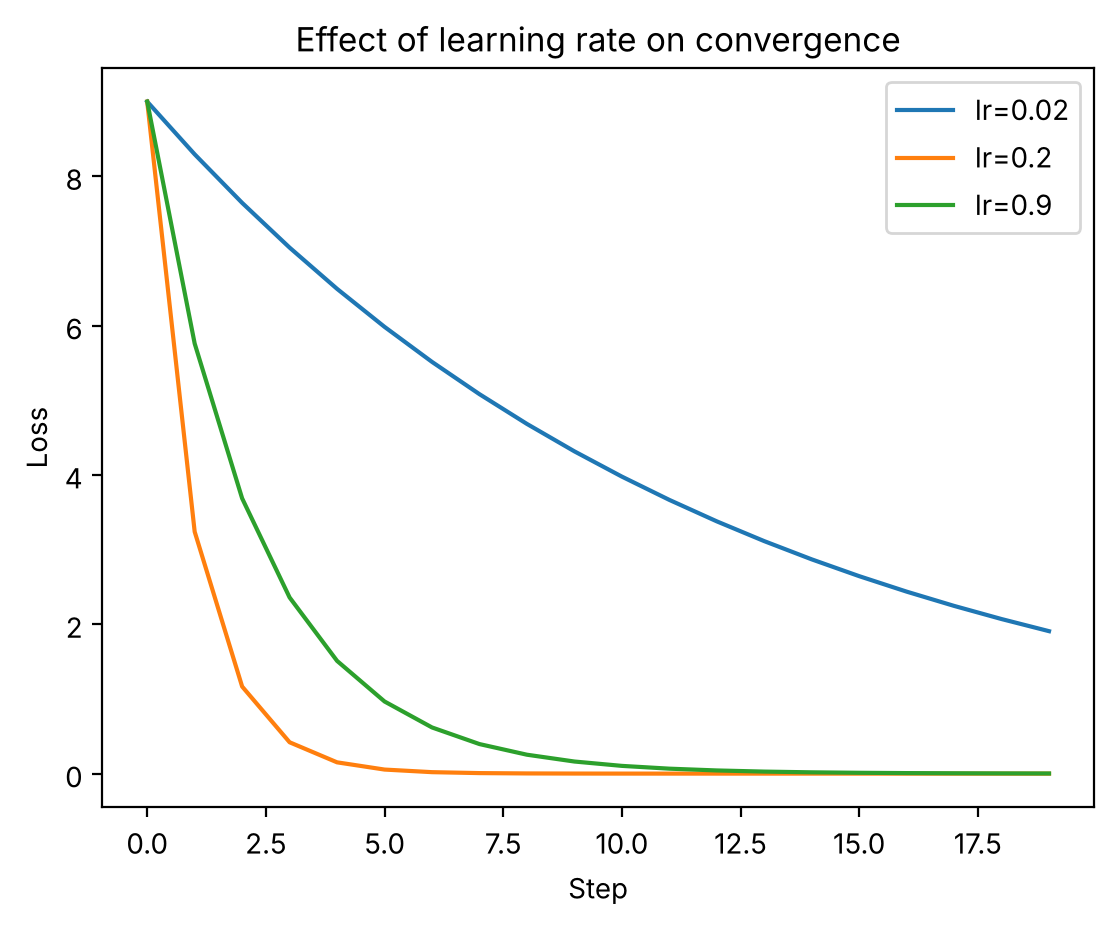

In [3]:

import matplotlib.pyplot as plt

def run_gd(lr, steps=20, w0=0.0):
    w = w0
    history = []
    for _ in range(steps):
        loss = (w - 3.0) ** 2
        grad = 2.0 * (w - 3.0)
        history.append((w, loss))
        w = w - lr * grad
    return np.array(history)

for lr in [0.02, 0.2, 0.9]:
    hist = run_gd(lr)
    plt.plot(hist[:, 1], label=f"lr={lr}")

plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Effect of learning rate on convergence")
plt.legend()
plt.show()


## Group 1: Mathematical Understanding (Sultan Atanda)

### The five ideas in plain words

- **Loss function.** One number that says how wrong the model is. MSE squares each error and averages them, so big mistakes count much more than small ones. Training means finding the parameters that make this number as small as possible.
- **Gradient.** The list of partial derivatives of the loss, one per parameter. Each entry says how fast the loss changes if we nudge that one parameter. Together they point in the direction where the loss rises fastest.
- **Parameter update.** $\theta \leftarrow \theta - \eta \nabla_\theta \mathcal{L}$. We take a step against the gradient, so the loss goes down. A parameter with a large gradient gets a large correction, and one with a zero gradient is left alone.
- **Learning rate $\eta$.** The gradient gives the direction and the local slope. The learning rate decides how far we trust that local picture. Too small wastes time, too large jumps past the valley.
- **Backpropagation vs gradient descent.** They are not two learning rules. Gradient descent is the *update rule*. Backpropagation is the *method for computing the gradient* in a layered network, using the chain rule from the output back to the input. Backprop answers "which way?", gradient descent takes the step.

### One update of the single neuron, by hand

Model $\hat{y} = wx + b$, starting at $w = 0$, $b = 0$, $\eta = 0.1$ (the setup of the NumPy cell in Section 4).

**One data point**, $x = 2$, $y = 5$:

| Step | Calculation | Value |
|---|---|---|
| Forward pass | $\hat{y} = 0 \cdot 2 + 0$ | $0$ |
| Loss | $(\hat{y} - y)^2 = (0 - 5)^2$ | $25$ |
| $\partial L / \partial w$ | $2(\hat{y} - y)x = 2(-5)(2)$ | $-20$ |
| $\partial L / \partial b$ | $2(\hat{y} - y) = 2(-5)$ | $-10$ |
| New $w$ | $0 - 0.1(-20)$ | $2.0$ |
| New $b$ | $0 - 0.1(-10)$ | $1.0$ |

Both gradients are negative, so both parameters go up, which is the right direction for $y = 2x + 1$. On this single point the step lands exactly on the true values, which is a coincidence of the numbers chosen.

**All four points** ($x = [0, 1, 2, 3]$, $y = [1, 3, 5, 7]$). With MSE the gradient is the average of the per-point gradients:

- Loss: $\frac{1}{4}(1^2 + 3^2 + 5^2 + 7^2) = \frac{84}{4} = 21$
- $\frac{\partial L}{\partial w} = \frac{2}{4}\sum(\hat{y}_i - y_i)x_i = \frac{2}{4}(0 - 3 - 10 - 21) = -17$
- $\frac{\partial L}{\partial b} = \frac{2}{4}\sum(\hat{y}_i - y_i) = \frac{2}{4}(-16) = -8$
- New values: $w = 0 + 0.1 \cdot 17 = 1.7$ and $b = 0 + 0.1 \cdot 8 = 0.8$

This matches the first line printed by the NumPy cell in Section 4: `loss = 21.0000 | w = 1.7000 | b = 0.8000`.

In [4]:
import numpy as np

x_np = np.array([0.0, 1.0, 2.0, 3.0])
y_np = np.array([1.0, 3.0, 5.0, 7.0])
w0, b0, lr = 0.0, 0.0, 0.1

err = (w0 * x_np + b0) - y_np
hand = {"loss": np.mean(err ** 2), "dL/dw": np.mean(2 * err * x_np), "dL/db": np.mean(2 * err)}
hand["w_new"] = w0 - lr * hand["dL/dw"]
hand["b_new"] = b0 - lr * hand["dL/db"]
for k, v in hand.items():
    print(f"{k:6s} = {v:7.3f}")

loss   =  21.000
dL/dw  = -17.000
dL/db  =  -8.000
w_new  =   1.700
b_new  =   0.800


### The chain rule for a first-layer weight

For the two-layer network of Section 5 with one output and squared error,

$$
z^{[1]} = W^{[1]}x + b^{[1]}, \quad a^{[1]} = \sigma(z^{[1]}), \quad \hat{y} = W^{[2]}a^{[1]} + b^{[2]}, \quad L = (\hat{y} - y)^2
$$

the weight $W^{[1]}_{jk}$ connects input $k$ to hidden unit $j$. It only reaches the loss through $z^{[1]}_j \to a^{[1]}_j \to \hat{y} \to L$, so

$$
\frac{\partial L}{\partial W^{[1]}_{jk}}
= \underbrace{2(\hat{y} - y)}_{\partial L / \partial \hat{y}}
\cdot \underbrace{W^{[2]}_{j}}_{\partial \hat{y} / \partial a^{[1]}_j}
\cdot \underbrace{\sigma'(z^{[1]}_j)}_{\partial a^{[1]}_j / \partial z^{[1]}_j}
\cdot \underbrace{x_k}_{\partial z^{[1]}_j / \partial W^{[1]}_{jk}}
$$

| Factor | Meaning |
|---|---|
| $2(\hat{y} - y)$ | How wrong the output is, and in which direction |
| $W^{[2]}_j$ | How much hidden unit $j$ matters to the output |
| $\sigma'(z^{[1]}_j)$ | How sensitive the activation is at its current input |
| $x_k$ | How much input $k$ was present in this example |

If any factor is zero, the weight does not learn from this example. That is why one hidden unit in Section 12 has a gradient of exactly 0: its ReLU input was negative for all three points, so $\sigma' = 0$. The same product also explains vanishing gradients. The derivative of a sigmoid is at most 0.25, so every extra sigmoid layer multiplies the gradient by a number no bigger than 0.25.

The cell below checks this formula against PyTorch autograd on a small tanh network.

In [5]:
import torch

torch.manual_seed(3)
x_in = torch.tensor([0.5, -1.2])
y_true = torch.tensor(0.8)
W1 = torch.randn(3, 2, requires_grad=True)
b1 = torch.randn(3, requires_grad=True)
W2 = torch.randn(3, requires_grad=True)
b2 = torch.randn(1, requires_grad=True)

z1 = W1 @ x_in + b1
a1 = torch.tanh(z1)
y_hat = W2 @ a1 + b2
loss = (y_hat - y_true).pow(2).sum()
loss.backward()

j, k = 1, 0
by_hand = 2 * (y_hat - y_true) * W2[j] * (1 - torch.tanh(z1[j]) ** 2) * x_in[k]
print(f"chain rule by hand: {by_hand.item():.6f}")
print(f"autograd:           {W1.grad[j, k].item():.6f}")

chain rule by hand: -0.022900
autograd:           -0.022900


### Reading the learning-rate plot in Section 7

For $L(w) = (w - 3)^2$ the update is $w_{t+1} = w_t - 2\eta(w_t - 3)$. Subtracting 3 from both sides:

$$
w_{t+1} - 3 = (1 - 2\eta)(w_t - 3)
$$

So the distance to the minimum is multiplied by the same factor every step, and the loss by that factor squared.

| $\eta$ | Factor $1 - 2\eta$ | Loss factor $(1 - 2\eta)^2$ | What happens |
|---|---|---|---|
| 0.02 | 0.96 | 0.92 | Slow: only 4% closer each step |
| 0.2 | 0.6 | 0.36 | Fast and smooth |
| 0.9 | −0.8 | 0.64 | $w$ jumps to the other side of 3 every step, but each jump is smaller |
| above 1 | below −1 | above 1 | Each jump is bigger than the last: divergence |

What surprised me is that the loss curve for $\eta = 0.9$ in Section 7 looks smooth, and it falls faster than $\eta = 0.02$. The zigzag is only visible in $w$ itself, because squaring the error hides its sign. The chart below shows the path of $w$, which the loss plot hides.

In [6]:
import plotly.graph_objects as go

fig = go.Figure()
for lr in [0.02, 0.2, 0.9]:
    w, path = 0.0, [0.0]
    for _ in range(20):
        w = w - lr * 2 * (w - 3)
        path.append(w)
    fig.add_trace(go.Scatter(x=list(range(21)), y=path, mode="lines+markers", name=f"lr = {lr}"))
fig.add_hline(y=3, line_dash="dot", annotation_text="minimum w = 3")
fig.update_layout(title="Path of w for the three learning rates of Section 7",
                  xaxis_title="Step", yaxis_title="w", template="plotly_white", width=850, height=450)
fig.show()

### One formula behind everyone's results

When the model has a weight **and** a bias, the loss is a bowl that can be steep in one direction and nearly flat in another. For MSE on John's and Eche's data ($x = [1, 2, 3, 4]$) the curvature of that bowl is the matrix of second derivatives (the Hessian):

$$
H = \frac{2}{n}\begin{bmatrix} \sum x_i^2 & \sum x_i \\ \sum x_i & n \end{bmatrix} = \begin{bmatrix} 15 & 5 \\ 5 & 2 \end{bmatrix}
$$

Gradient descent shrinks the error along each eigenvector of $H$ by $(1 - \eta\lambda)$, the same idea as the $(1 - 2\eta)$ factor above and Antonio's $(1 - 15\eta)$ in Challenge A, where 15 is the single curvature of a one-weight model. The cell below computes the two curvatures.

In [7]:
x_tf = np.array([1.0, 2.0, 3.0, 4.0])
H = (2 / len(x_tf)) * np.array([[np.sum(x_tf ** 2), np.sum(x_tf)], [np.sum(x_tf), len(x_tf)]])
lam = np.linalg.eigvalsh(H)
print("curvatures (eigenvalues):", np.round(lam, 3))
print(f"largest stable learning rate 2/lambda_max = {2 / lam[-1]:.3f}")
print(f"condition number = {lam[-1] / lam[0]:.1f}")
for lr in [0.01, 0.05]:
    print(f"lr = {lr}: slow direction keeps {1 - lr * lam[0]:.4f} of its error each epoch")

curvatures (eigenvalues): [ 0.299 16.701]
largest stable learning rate 2/lambda_max = 0.120
condition number = 55.8
lr = 0.01: slow direction keeps 0.9970 of its error each epoch
lr = 0.05: slow direction keeps 0.9850 of its error each epoch


This explains three results from the team sections:

- **John's divergence.** The steep direction has curvature 16.7, so any $\eta > 2/16.7 \approx 0.12$ overshoots by more than it corrects. John's $\eta = 0.2$ is above that limit, and the loss reached $10^{22}$.
- **John's bias stuck at 0.70 after 300 epochs.** The flat direction has curvature 0.3. At $\eta = 0.01$ that direction keeps 99.7% of its error every epoch, so it barely moves. The flat direction points mostly along the bias (eigenvector about $(-0.32, 0.95)$ in $(w, b)$), which is why the bias is the slowest parameter to settle.
- **Eche needing 2,000 epochs at 0.01, or a faster rate.** Same reason: the condition number is about 56, so a learning rate small enough for the steep direction is very slow for the flat one. Raising $\eta$ to 0.05 makes the flat direction about five times faster while staying under the 0.12 limit.

### Notes on the workshop markdown

While working through the theory I found a few mistakes in the original cells. We left them as they are and list them here:

1. **Section 1** says "$\theta$ is the learning rate". It should say $\eta$ is the learning rate; $\theta$ is the parameters.
2. **Sections 1, 2, 6, 7 and 14** mix `\( \)` and `\[ \]` with `$ $` for maths. Some viewers, including GitHub's preview, can show the `\( \)` ones as plain text.
3. **Section 8** prints `w` after the update but `loss` from before it. That is why step 1 shows `w = 0.6` next to `loss = 9.0`, which is the loss at `w = 0`.
4. **Workshop Structure** says "Instructor-led walkthrough of Vector Space Proximity". That line comes from a different workshop.

### Insights (Sultan)

1. **One number decides stability.** In every experiment in this notebook, the error was multiplied by a fixed factor per step: $(1 - 2\eta)$ in Section 7, $(1 - 15\eta)$ in Antonio's Challenge A and $(1 - \eta\lambda)$ for John and Eche. Knowing the curvature tells you the safe learning rate before training.
2. **A smooth loss curve does not mean a smooth path.** With $\eta = 0.9$ the loss falls steadily while $w$ jumps from one side of the minimum to the other. Watching only the loss can hide oscillation in the parameters.
3. **Slow training is often a shape problem, not a learning-rate problem.** The bias in John's and Eche's runs was slow because the bowl is 56 times steeper in one direction than the other. Raising the learning rate only helps up to the limit of the steep direction. Past that limit, training diverges.


## 8. PyTorch part I: tensors, autograd, and a manual gradient step

PyTorch tracks operations on tensors when `requires_grad=True`.  
After a forward computation produces a scalar loss, calling `.backward()` computes gradients for all tracked parameters.

This is convenient because:
- we write the forward computation naturally,
- PyTorch builds the computational graph,
- autograd applies reverse-mode automatic differentiation.


In [8]:
import torch

torch.manual_seed(42)

# One parameter: w
w = torch.tensor([0.0], requires_grad=True)
target = torch.tensor([3.0])
learning_rate = 0.1

for step in range(10):
    loss = (w - target).pow(2).mean()
    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad

    print(f"step={step+1:2d} | w={w.item():.4f} | grad={w.grad.item():.4f} | loss={loss.item():.4f}")

    w.grad.zero_()


step= 1 | w=0.6000 | grad=-6.0000 | loss=9.0000
step= 2 | w=1.0800 | grad=-4.8000 | loss=5.7600
step= 3 | w=1.4640 | grad=-3.8400 | loss=3.6864
step= 4 | w=1.7712 | grad=-3.0720 | loss=2.3593
step= 5 | w=2.0170 | grad=-2.4576 | loss=1.5099
step= 6 | w=2.2136 | grad=-1.9661 | loss=0.9664
step= 7 | w=2.3709 | grad=-1.5729 | loss=0.6185
step= 8 | w=2.4967 | grad=-1.2583 | loss=0.3958
step= 9 | w=2.5973 | grad=-1.0066 | loss=0.2533
step=10 | w=2.6779 | grad=-0.8053 | loss=0.1621



### Discussion prompt
Why do we use `torch.no_grad()` during the parameter update?

Because the update itself is **not** part of the model's forward computation for the next loss evaluation.  
We want to change parameter values without asking PyTorch to differentiate through the update rule itself.



## 9. PyTorch part II: linear regression with gradient descent

We now fit a simple model:

$$
\hat{y} = wx + b
$$

using PyTorch tensors and autograd.


Learned w = 1.9855, b = 0.9474


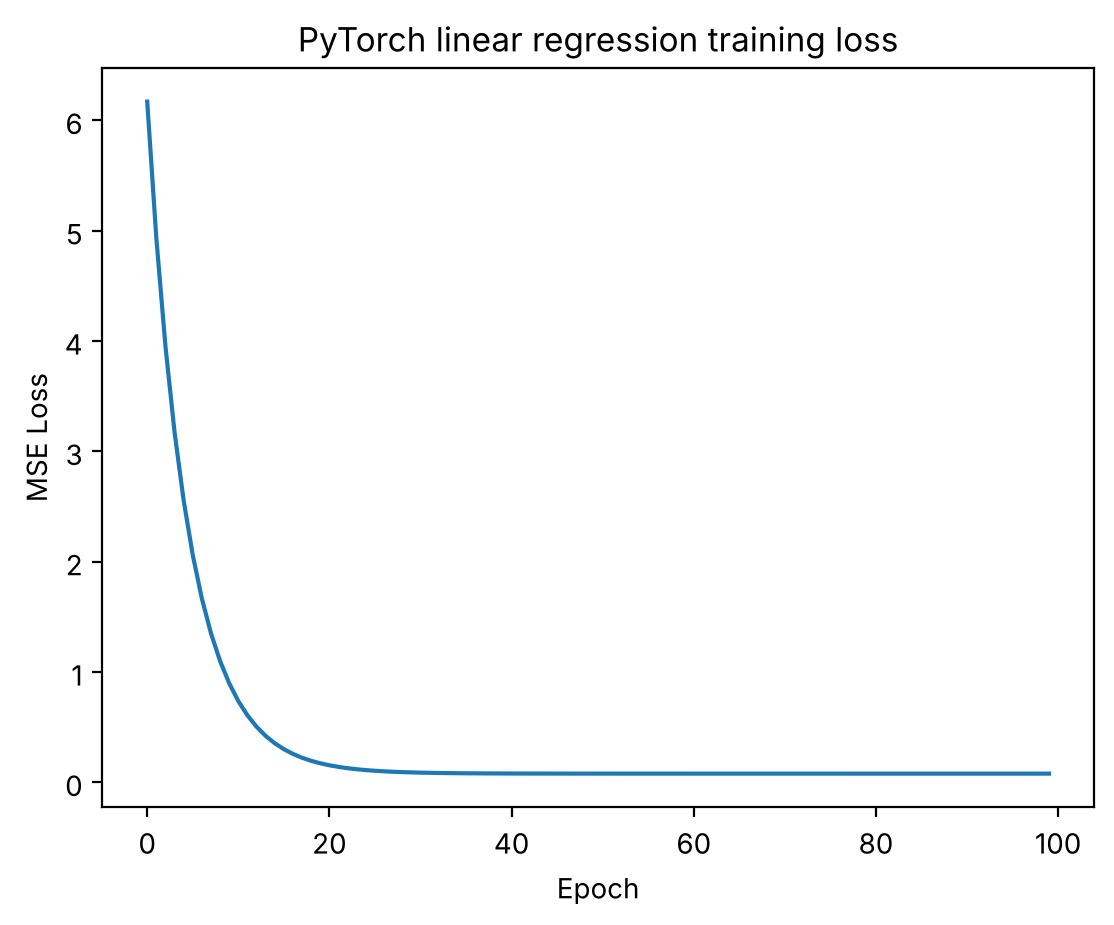

In [9]:

import torch
import matplotlib.pyplot as plt

torch.manual_seed(7)

# Synthetic data: y = 2x + 1 + noise
x = torch.linspace(-2, 2, 100).reshape(-1, 1)
noise = 0.3 * torch.randn_like(x)
y = 2 * x + 1 + noise

w = torch.randn(1, requires_grad=True)
b = torch.randn(1, requires_grad=True)

learning_rate = 0.05
epochs = 100
loss_history = []

for epoch in range(epochs):
    y_hat = x * w + b
    loss = ((y_hat - y) ** 2).mean()
    loss.backward()

    with torch.no_grad():
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad

    w.grad.zero_()
    b.grad.zero_()

    loss_history.append(loss.item())

print(f"Learned w = {w.item():.4f}, b = {b.item():.4f}")

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("PyTorch linear regression training loss")
plt.show()



## 10. PyTorch part III: using `nn.Module` and `torch.optim.SGD`

This is closer to how real neural network training is usually written in PyTorch:
- define a model with `nn.Module`,
- define a loss function,
- choose an optimizer,
- run forward pass, backward pass, optimizer step.


In [10]:

import torch
import torch.nn as nn

torch.manual_seed(0)

x = torch.linspace(-2, 2, 100).reshape(-1, 1)
y = 2 * x + 1 + 0.3 * torch.randn_like(x)

model = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

loss_history = []

for epoch in range(100):
    preds = model(x)
    loss = criterion(preds, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

print("Learned parameters:")
for name, param in model.named_parameters():
    print(name, param.detach().numpy().ravel())


Learned parameters:
weight [1.9997989]
bias [1.0111167]


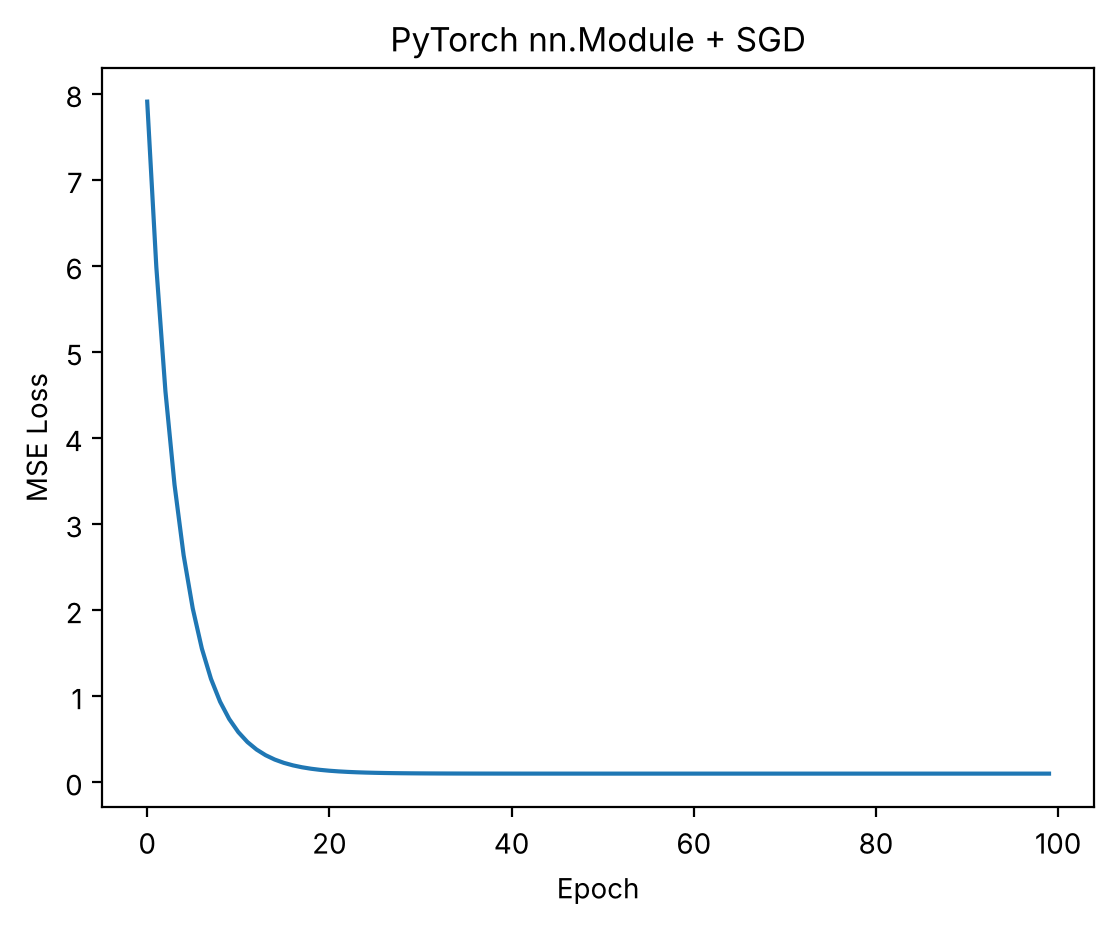

In [11]:

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("PyTorch nn.Module + SGD")
plt.show()



## 11. PyTorch part IV: a small multi-layer network

Now we move from a single linear neuron to a small multi-layer perceptron (MLP).  
This lets students see that the same gradient descent logic still works, but the gradient computation is handled through backpropagation automatically.


In [12]:

import torch
import torch.nn as nn

torch.manual_seed(123)

# Nonlinear regression dataset
x = torch.linspace(-3, 3, 200).reshape(-1, 1)
y = torch.sin(x) + 0.1 * torch.randn_like(x)

model = nn.Sequential(
    nn.Linear(1, 16),
    nn.Tanh(),
    nn.Linear(16, 16),
    nn.Tanh(),
    nn.Linear(16, 1)
)

criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.03)

loss_history = []

for epoch in range(300):
    preds = model(x)
    loss = criterion(preds, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

print(f"Final loss: {loss_history[-1]:.4f}")


Final loss: 0.0401


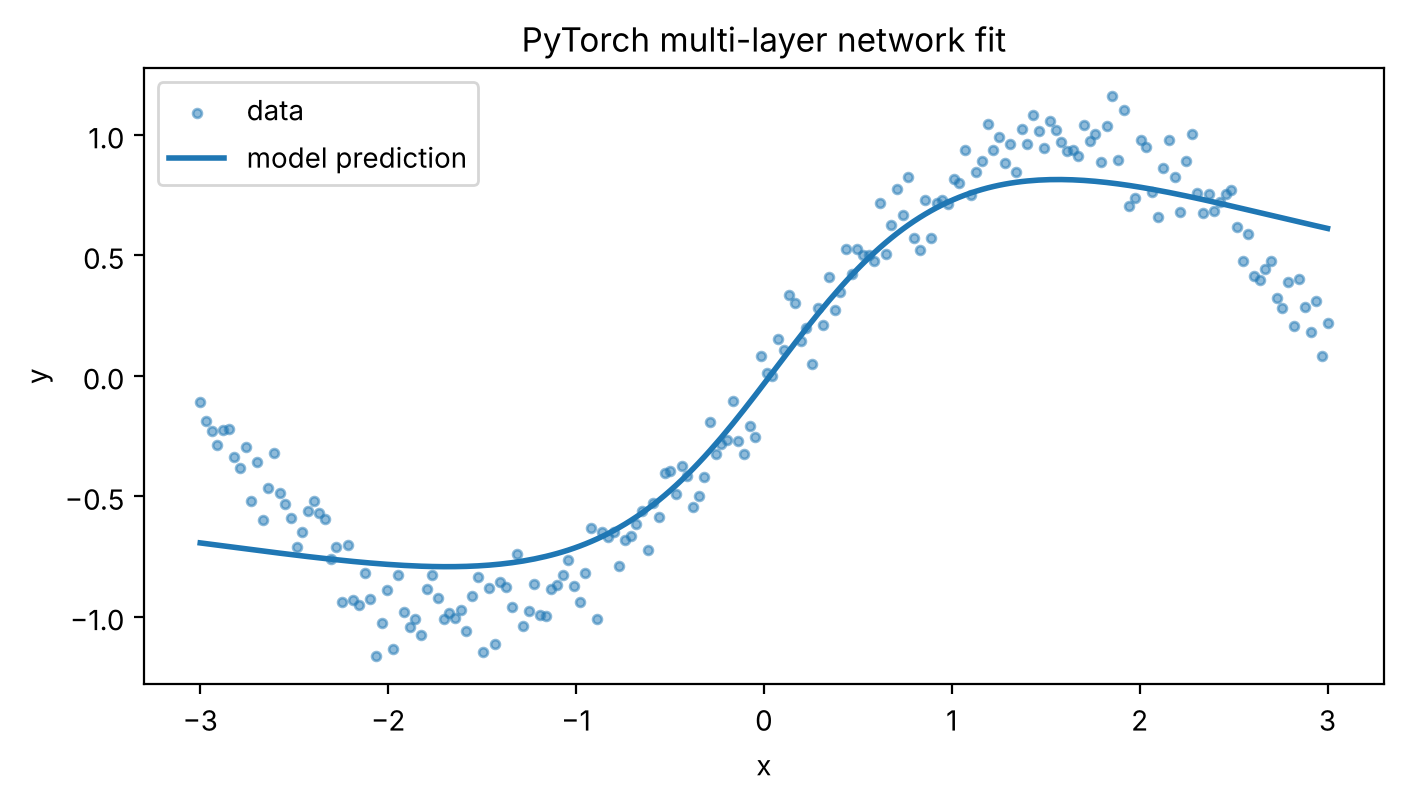

In [13]:

with torch.no_grad():
    preds = model(x)

plt.figure(figsize=(8, 4))
plt.scatter(x.numpy(), y.numpy(), s=10, alpha=0.5, label="data")
plt.plot(x.numpy(), preds.numpy(), linewidth=2, label="model prediction")
plt.xlabel("x")
plt.ylabel("y")
plt.title("PyTorch multi-layer network fit")
plt.legend()
plt.show()



## 12. Inspecting gradients in PyTorch

One useful teaching move is to explicitly inspect gradients after `backward()`.


In [14]:

torch.manual_seed(1)

model = nn.Sequential(
    nn.Linear(1, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)

x_small = torch.tensor([[1.0], [2.0], [3.0]])
y_small = torch.tensor([[2.0], [4.0], [6.0]])

criterion = nn.MSELoss()

preds = model(x_small)
loss = criterion(preds, y_small)
loss.backward()

for name, param in model.named_parameters():
    print(f"{name:20s} | grad shape: {tuple(param.grad.shape)}")
    print(param.grad)
    print("-" * 60)


0.weight             | grad shape: (4, 1)
tensor([[-1.1462],
        [ 0.0736],
        [ 0.0000],
        [-0.4364]])
------------------------------------------------------------
0.bias               | grad shape: (4,)
tensor([-0.4404,  0.0736,  0.0000, -0.1859])
------------------------------------------------------------
2.weight             | grad shape: (1, 4)
tensor([[ -2.5321,  -0.1903,   0.0000, -12.1389]])
------------------------------------------------------------
2.bias               | grad shape: (1,)
tensor([-7.5377])
------------------------------------------------------------



## 13. Algorithm summary

### Generic gradient descent
1. Initialize parameters.
2. Repeat until stopping condition:
   1. Run forward pass.
   2. Compute loss.
   3. Compute gradients of loss with respect to parameters.
   4. Update parameters in the negative gradient direction.

### In neural networks
1. Forward pass through all layers.
2. Loss computation.
3. Backpropagation.
4. Parameter update.
5. Repeat over many epochs.

### Common stopping conditions
- fixed number of epochs,
- validation loss stops improving,
- gradients become very small,
- training budget is exhausted.



## 14. Student challenge A — implement gradient descent manually in PyTorch

Complete the TODOs below.

**Goal:** Train a single-parameter model \( \hat{y} = wx \) on a tiny dataset using a manual gradient descent loop with autograd.


In [15]:

# CHALLENGE A: Manual gradient descent in PyTorch
# Students: fill in the TODOs.

import torch

torch.manual_seed(0)

x = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
y = torch.tensor([[2.0], [4.0], [6.0], [8.0]])

w = torch.randn(1, 1, requires_grad=True)
learning_rate = 0.01

for epoch in range(200):
    # TODO 1: compute predictions
    y_hat = x @ w

    # TODO 2: compute mean squared error loss
    loss = ((y_hat - y) ** 2).mean()

    # TODO 3: backpropagate
    loss.backward()

    # TODO 4: update the parameter inside a no_grad block
    with torch.no_grad():
        w -= learning_rate * w.grad

    # TODO 5: reset gradients
    w.grad.zero_()

print("Learned weight:", w.detach().numpy())
print("Final loss:", loss.item())


Learned weight: [[1.9999996]]
Final loss: 8.988365607365267e-13


## Group 1: Challenge A, PyTorch (Antonio Sainz)

**Gradient Descent Workshop · CSCN8010 · Group 1 · Antonio Sainz · 9072844**

This notebook covers the PyTorch part of the workshop:

1. Challenge A — manual gradient descent with autograd, with each of the five training steps explained.
2. What goes wrong when `w.grad.zero_()` is removed.
3. Challenge A rewritten with `torch.optim.SGD` and `nn.MSELoss`, checked against the manual version.
4. Challenge A trained with three learning rates.
5. Insights from these runs. His answers to Q6, Q9 and Q10 are in the reflection section.

**Data.** The four points used by the workshop, $x = [1, 2, 3, 4]$ and $y = [2, 4, 6, 8]$. They follow $y = 2x$ exactly, so the ideal weight is $w = 2$ and the ideal loss is 0. The model has a single weight and no bias: $\hat{y} = xw$.

In [16]:
import torch
import torch.nn as nn
import plotly.graph_objects as go

print("PyTorch version:", torch.__version__)

# Workshop data for Challenge A: y = 2x
x = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
y = torch.tensor([[2.0], [4.0], [6.0], [8.0]])

# Same starting weight for every experiment, so the comparisons are fair
torch.manual_seed(0)
w_init = torch.randn(1, 1)
print("Initial weight:", round(w_init.item(), 4))

PyTorch version: 2.15.0+cpu
Initial weight: 1.541


### A1. Challenge A — manual gradient descent with autograd

For the loss $L(w) = \frac{1}{n}\sum_i (x_i w - y_i)^2$ the gradient is $\frac{\partial L}{\partial w} = \frac{2}{n}\sum_i x_i (x_i w - y_i)$. PyTorch computes this value for us through autograd. Each epoch runs the same five steps:

| Step | Code | What it does |
|---|---|---|
| 1. Forward pass | `y_hat = x @ w` | Predicts with the current weight; PyTorch records the operation in a graph because `w` has `requires_grad=True`. |
| 2. Loss | `((y_hat - y) ** 2).mean()` | Measures the error as mean squared error (MSE), a single number. |
| 3. Backward | `loss.backward()` | Walks the graph backwards and stores $\partial L / \partial w$ in `w.grad`. |
| 4. Update | `w -= lr * w.grad` inside `torch.no_grad()` | Moves the weight against the gradient. `no_grad` stops the update itself from being recorded as part of the model. |
| 5. Reset | `w.grad.zero_()` | Clears the stored gradient, because PyTorch adds new gradients to the old ones. |

The training loop is written as a function so the same code can be reused for the next experiments.

In [17]:
def train_manual(lr=0.01, epochs=200, reset_grad=True):
    # Returns the learned weight and the loss of every epoch
    w = w_init.clone().requires_grad_(True)
    losses = []
    for epoch in range(epochs):
        y_hat = x @ w                        # 1. forward pass: prediction with the current weight
        loss = ((y_hat - y) ** 2).mean()     # 2. MSE loss
        loss.backward()                      # 3. autograd fills w.grad with dL/dw

        with torch.no_grad():                # 4. update outside the graph
            w -= lr * w.grad

        if reset_grad:
            w.grad.zero_()                   # 5. clear the gradient for the next epoch
        losses.append(loss.item())
    return w.detach(), losses


w_manual, loss_manual = train_manual(lr=0.01, epochs=200)
print(f"Learned weight: {w_manual.item():.6f}   (true value 2)")
print(f"Loss at epoch 1:   {loss_manual[0]:.6f}")
print(f"Loss at epoch 200: {loss_manual[-1]:.2e}")

Learned weight: 2.000000   (true value 2)
Loss at epoch 1:   1.580135
Loss at epoch 200: 8.99e-13


In [18]:
fig = go.Figure(go.Scatter(x=list(range(1, 201)), y=loss_manual, mode="lines", name="lr = 0.01"))
fig.update_layout(title="Challenge A: training loss (manual gradient descent)",
                  xaxis_title="Epoch", yaxis_title="MSE loss (log scale)",
                  yaxis_type="log", template="plotly_white", width=850, height=450)
fig.show()

The loss falls in a straight line on the log scale, which means it shrinks by roughly the same fraction every epoch. For this data that can be checked by hand: the gradient is $15(w-2)$, because $\frac{2}{n}\sum x_i^2 = \frac{2 \cdot 30}{4} = 15$. Each update therefore multiplies the error $(w-2)$ by $(1 - 15\eta) = 0.85$ when $\eta = 0.01$.

### A2. What happens without `w.grad.zero_()`

`loss.backward()` does not overwrite `w.grad`; it **adds** the new gradient to whatever is already stored. If step 5 is removed, the value used in epoch $t$ is the sum of every gradient computed so far, not the current one. The run below repeats Challenge A with the same starting weight and learning rate, changing only that line.

In [19]:
w_no_reset, loss_no_reset = train_manual(lr=0.01, epochs=200, reset_grad=False)
print(f"With zero_():    final weight = {w_manual.item():.6f}, final loss = {loss_manual[-1]:.2e}")
print(f"Without zero_(): final weight = {w_no_reset.item():.6f}, final loss = {loss_no_reset[-1]:.2e}")

epochs_axis = list(range(1, 201))
fig = go.Figure()
fig.add_trace(go.Scatter(x=epochs_axis, y=loss_manual, mode="lines", name="With w.grad.zero_()"))
fig.add_trace(go.Scatter(x=epochs_axis, y=loss_no_reset, mode="lines", name="Without w.grad.zero_()"))
fig.update_layout(title="Effect of not resetting gradients (same start, lr = 0.01)",
                  xaxis_title="Epoch", yaxis_title="MSE loss (log scale)",
                  yaxis_type="log", template="plotly_white", width=850, height=450)
fig.show()

With zero_():    final weight = 2.000000, final loss = 8.99e-13
Without zero_(): final weight = 2.432230, final loss = 8.26e-01


In [20]:
# First 12 epochs without the reset: the stored gradient keeps growing while the weight overshoots 2
w = w_init.clone().requires_grad_(True)
print("epoch | weight before | stored w.grad")
for epoch in range(12):
    loss = ((x @ w - y) ** 2).mean()
    loss.backward()
    print(f"{epoch + 1:5d} | {w.item():13.4f} | {w.grad.item():13.4f}")
    with torch.no_grad():
        w -= 0.01 * w.grad

epoch | weight before | stored w.grad
    1 |        1.5410 |       -6.8851
    2 |        1.6098 |      -12.7374
    3 |        1.7372 |      -16.6791
    4 |        1.9040 |      -18.1189
    5 |        2.0852 |      -16.8409
    6 |        2.2536 |      -13.0368
    7 |        2.3840 |       -7.2771
    8 |        2.4567 |       -0.4259
    9 |        2.4610 |        6.4892
   10 |        2.3961 |       12.4309
   11 |        2.2718 |       16.5080
   12 |        2.1067 |       18.1089


**Why the gradients pile up.** Without the reset, `w.grad` keeps the memory of all earlier steps. While the weight is below 2 every new gradient is negative, so the stored value keeps growing in size and the steps get longer even as the weight approaches 2. The weight passes 2, and only after several epochs of positive gradients does the stored sum change sign and pull it back. The table shows this: the weight overshoots to about 2.46 while the stored gradient is still negative.

The run never settles. Writing $e_t = w_t - 2$, the stored gradient is $15\sum_{k \le t} e_k$, which gives $e_{t+1} - 2e_t + e_{t-1} = -15\eta\, e_t$. That is the equation of an undamped oscillation: with $\eta = 0.01$ the error swings around 0 with a period of about 16 epochs, and its amplitude does not shrink. In the chart the loss keeps bouncing between about 1 and much smaller values for all 200 epochs, while the correct version reaches the precision limit of float32 (about $10^{-12}$) by epoch 90. The final values printed above confirm it. This is why PyTorch training loops call `optimizer.zero_grad()` (or `w.grad.zero_()`) on every iteration.

### A3. Challenge A with `torch.optim.SGD` and `nn.MSELoss`

The same model written the way PyTorch code is usually written: the weight is an `nn.Parameter`, `nn.MSELoss` computes the loss and `torch.optim.SGD` performs the update and the reset. It starts from the same weight with the same learning rate and number of epochs, so it should learn exactly the same value.

In [21]:
w_param = nn.Parameter(w_init.clone())
criterion = nn.MSELoss()
optimizer = torch.optim.SGD([w_param], lr=0.01)
loss_sgd = []

for epoch in range(200):
    loss = criterion(x @ w_param, y)   # forward pass + MSE in one line
    optimizer.zero_grad()              # replaces w.grad.zero_()
    loss.backward()                    # same autograd call as before
    optimizer.step()                   # replaces the manual no_grad update
    loss_sgd.append(loss.item())

print(f"Manual loop weight:  {w_manual.item():.8f}")
print(f"optim.SGD weight:    {w_param.item():.8f}")
print(f"Absolute difference: {abs(w_manual.item() - w_param.item()):.2e}")
print("Same weight:", torch.allclose(w_manual, w_param.detach()))
print("Same loss in every epoch:", torch.allclose(torch.tensor(loss_manual), torch.tensor(loss_sgd)))

Manual loop weight:  1.99999964
optim.SGD weight:    1.99999964
Absolute difference: 0.00e+00
Same weight: True
Same loss in every epoch: True


Both versions give the same weight and the same loss at every epoch. `optim.SGD` with no momentum applies exactly $w \leftarrow w - \eta \nabla_w L$, and `nn.MSELoss` uses the mean by default, just like `.mean()` in the manual loop. The optimizer only hides the update and reset steps; the mathematics does not change.

### A4. Challenge A with three learning rates

The same training run with $\eta = 0.001$, $0.01$ and $0.05$, all starting from the same weight for 200 epochs.

In [22]:
learning_rates = [0.001, 0.01, 0.05]
lr_results = {lr: train_manual(lr=lr, epochs=200) for lr in learning_rates}

print("learning rate | learned weight | final loss | first epoch with loss < 1e-6")
for lr, (w_lr, losses) in lr_results.items():
    first = next((i + 1 for i, v in enumerate(losses) if v < 1e-6), "not reached")
    print(f"{lr:13} | {w_lr.item():14.6f} | {losses[-1]:10.2e} | {first}")

fig = go.Figure()
for lr, (w_lr, losses) in lr_results.items():
    fig.add_trace(go.Scatter(x=epochs_axis, y=losses, mode="lines", name=f"lr = {lr}"))
fig.update_layout(title="Challenge A: loss for three learning rates",
                  xaxis_title="Epoch", yaxis_title="MSE loss (log scale)",
                  yaxis_type="log", template="plotly_white", width=850, height=450)
fig.show()

learning rate | learned weight | final loss | first epoch with loss < 1e-6
        0.001 |       1.977661 |   3.86e-03 | not reached
         0.01 |       2.000000 |   8.99e-13 | 45
         0.05 |       2.000000 |   0.00e+00 | 7


With this data each step multiplies the error by $(1 - 15\eta)$: about 0.985 for $\eta = 0.001$, 0.85 for $\eta = 0.01$ and 0.25 for $\eta = 0.05$. That is why the smallest learning rate is still away from the minimum after 200 epochs, while the largest reaches it in a few epochs. The flat part of the $\eta = 0.01$ curve near $10^{-12}$ is the precision limit of float32, not a problem with the optimization; with $\eta = 0.05$ the loss becomes exactly 0, so its line leaves the log-scale chart. The same formula shows the limit: for $\eta > 2/15 \approx 0.133$ the factor is below −1, so each step overshoots by more than it corrects and the loss grows instead of falling.

### Insights (Antonio)

In [23]:
from IPython.display import Markdown, display

lr_small = lr_results[0.001]
lr_large = lr_results[0.05]
first_large = next(i + 1 for i, v in enumerate(lr_large[1]) if v < 1e-6)
display(Markdown(f'''
1. **The learning rate can be predicted for a simple model.** Because the gradient is $15(w-2)$, the error shrinks by a fixed factor $(1-15\\eta)$ per step. The runs match this: with $\\eta=0.05$ the loss dropped below $10^{{-6}}$ at epoch {first_large}, while with $\\eta=0.001$ the weight was still {lr_small[0].item():.4f} after 200 epochs. In larger networks this curvature is unknown, which is why the learning rate has to be tuned by experiment.
2. **A training bug does not always crash the code.** Removing `w.grad.zero_()` raised no error and the weight stayed close to the right region ({w_no_reset.item():.4f} at the end), but the loss was still {loss_no_reset[-1]:.2f} after 200 epochs, against {loss_manual[-1]:.1e} for the correct loop. Only the loss curve shows that the weight is swinging around 2 instead of converging. Plotting the loss every epoch is a cheap way to detect this kind of silent error.
3. **High-level PyTorch code is the same algorithm.** `nn.MSELoss` plus `optim.SGD` reproduced the manual loop exactly (difference {abs(w_manual.item() - w_param.item()):.1e}). Writing the manual version first makes it clear what `zero_grad`, `backward` and `step` actually do, which helps when debugging bigger models.
'''))


1. **The learning rate can be predicted for a simple model.** Because the gradient is $15(w-2)$, the error shrinks by a fixed factor $(1-15\eta)$ per step. The runs match this: with $\eta=0.05$ the loss dropped below $10^{-6}$ at epoch 7, while with $\eta=0.001$ the weight was still 1.9777 after 200 epochs. In larger networks this curvature is unknown, which is why the learning rate has to be tuned by experiment.
2. **A training bug does not always crash the code.** Removing `w.grad.zero_()` raised no error and the weight stayed close to the right region (2.4322 at the end), but the loss was still 0.83 after 200 epochs, against 9.0e-13 for the correct loop. Only the loss curve shows that the weight is swinging around 2 instead of converging. Plotting the loss every epoch is a cheap way to detect this kind of silent error.
3. **High-level PyTorch code is the same algorithm.** `nn.MSELoss` plus `optim.SGD` reproduced the manual loop exactly (difference 0.0e+00). Writing the manual version first makes it clear what `zero_grad`, `backward` and `step` actually do, which helps when debugging bigger models.



## 15. Student challenge B — TensorFlow implementation with `tf.GradientTape`

In TensorFlow, the analogous idea is to:
- open a `GradientTape`,
- compute the forward pass and loss inside the tape,
- ask the tape for gradients,
- update variables.

Students should connect the mathematical update rule to the framework-specific API.


In [24]:

# CHALLENGE B: Implement gradient descent in TensorFlow
# Uncomment and complete if TensorFlow is installed in your environment.

# import tensorflow as tf
#
# tf.random.set_seed(0)
#
# x = tf.constant([[1.0], [2.0], [3.0], [4.0]])
# y = tf.constant([[3.0], [5.0], [7.0], [9.0]])   # target: y = 2x + 1
#
# W = tf.Variable(tf.random.normal((1, 1)))
# b = tf.Variable(tf.zeros((1,)))
# learning_rate = 0.01
#
# for epoch in range(300):
#     with tf.GradientTape() as tape:
#         # TODO 1: forward pass
#         y_hat = tf.matmul(x, W) + b
#
#         # TODO 2: mean squared error
#         loss = tf.reduce_mean(tf.square(y_hat - y))
#
#     # TODO 3: compute gradients with respect to W and b
#     dW, db = tape.gradient(loss, [W, b])
#
#     # TODO 4: update parameters
#     W.assign_sub(learning_rate * dW)
#     b.assign_sub(learning_rate * db)
#
#     if epoch % 50 == 0:
#         print(f"epoch={epoch}, loss={loss.numpy():.4f}")
#
# print("Learned W:", W.numpy())
# print("Learned b:", b.numpy())



### TensorFlow extension challenge
Modify the TensorFlow code so that:
1. the data contains random noise,
2. training runs with mini-batches using `tf.data.Dataset`,
3. you store the loss after every epoch and plot it.

**Questions**
- Does noise make convergence less smooth?
- How does mini-batch training change the behavior of the optimization path?


## Group 1: Challenge B, TensorFlow (John Buni)

TensorFlow gradient descent with `tf.GradientTape`: the base challenge, the extension challenge (noise, `tf.data` mini-batches, loss per epoch) and a test with a learning rate that is too large. His answers to Q7, Q8 and Q11 are in the reflection section.

In [25]:
import tensorflow as tf
import numpy as np
import plotly.graph_objects as go

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### B1. Challenge B — Full-Batch Gradient Descent

The objective is to train a linear regression model using TensorFlow's GradientTape to learn the relationship y = 2x + 1.

The model uses Mean Squared Error (MSE) as its loss function and manually updates its weight and bias using gradient descent.

In [26]:
# Reproducible initialization
tf.random.set_seed(0)

# Training dataset: y = 2x + 1
x = tf.constant([[1.0], [2.0], [3.0], [4.0]])
y = tf.constant([[3.0], [5.0], [7.0], [9.0]])

W = tf.Variable(tf.random.normal((1, 1)))
b = tf.Variable(tf.zeros((1,)))

learning_rate = 0.01
epochs = 300
loss_history = []

for epoch in range(epochs):

    # GradientTape records operations involving trainable variables
    with tf.GradientTape() as tape:
        y_hat = tf.matmul(x, W) + b
        loss = tf.reduce_mean(tf.square(y_hat - y))

    # Returns the derivatives of loss with respect to W and b
    dW, db = tape.gradient(loss, [W, b])

    # Update parameters in the negative gradient direction
    W.assign_sub(learning_rate * dW)
    b.assign_sub(learning_rate * db)

    # Record loss after the parameter update
    epoch_loss = tf.reduce_mean(
        tf.square(tf.matmul(x, W) + b - y)
    )

    loss_history.append(float(epoch_loss.numpy()))

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}: Loss = {epoch_loss.numpy():.6f}")

print("\nLearned W:", W.numpy().item())
print("Learned b:", b.numpy().item())
print("True W: 2.0")
print("True b: 1.0")
print("Final loss:", loss_history[-1])

Epoch 50: Loss = 0.069099


Epoch 100: Loss = 0.051198
Epoch 150: Loss = 0.037934


Epoch 200: Loss = 0.028107
Epoch 250: Loss = 0.020826


Epoch 300: Loss = 0.015430

Learned W: 2.1033825874328613
Learned b: 0.6960417628288269
True W: 2.0
True b: 1.0
Final loss: 0.015430379658937454


#### B1.1 Training Loss Visualization

In [27]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=list(range(1, epochs + 1)),
    y=loss_history,
    mode="lines",
    name="Full-Batch Loss"
))

fig.update_layout(
    title="TensorFlow Gradient Descent - Training Loss",
    xaxis_title="Epoch",
    yaxis_title="Mean Squared Error",
    template="plotly_white"
)

fig.show()

#### B1.2 Learned vs True Parameters

In [28]:
fig = go.Figure()

fig.add_trace(go.Bar(
    name="True Parameters",
    x=["Weight (W)", "Bias (b)"],
    y=[2.0, 1.0]
))

fig.add_trace(go.Bar(
    name="Learned Parameters",
    x=["Weight (W)", "Bias (b)"],
    y=[W.numpy().item(), b.numpy().item()]
))

fig.update_layout(
    title="Learned vs True Model Parameters",
    yaxis_title="Parameter Value",
    barmode="group",
    template="plotly_white"
)

fig.show()

#### Observations

- The training loss decreased consistently throughout all 300 epochs,
  reaching a final MSE of 0.015430.
- The learned weight of 2.1034 is close to the true weight of 2.0.
- The learned bias of 0.6960 is approaching the true bias of 1.0.
- The model has not fully converged, but the decreasing loss suggests
  that additional epochs could improve parameter accuracy.
- The learning rate of 0.01 produces stable updates without divergence.

### B2. TensorFlow Extension Challenge

This experiment investigates how random noise and mini-batch training affect gradient descent convergence.

Three configurations are compared:

- Full-batch training with clean data.
- Full-batch training with noisy data.
- Mini-batch training with noisy data.

In [29]:
# Generate reproducible random noise
noise = tf.random.stateless_normal(
    shape=y.shape,
    seed=[42, 0],
    mean=0.0,
    stddev=0.5
)

y_noisy = y + noise

print("Original targets:", y.numpy().flatten())
print("Random noise:", noise.numpy().flatten())
print("Noisy targets:", y_noisy.numpy().flatten())

Original targets: [3. 5. 7. 9.]
Random noise: [ 0.00790854 -0.79504347  0.05179723  0.40587297]
Noisy targets: [3.0079086 4.2049565 7.0517974 9.405873 ]


#### B2.1 Full-Batch and Mini-Batch Training

All experiments use the same initial parameters, learning rate, and number of epochs to ensure a consistent comparison.

In [30]:
# Use identical starting parameters for all experiments
tf.random.set_seed(0)
initial_W = tf.random.normal((1, 1))
initial_b = tf.zeros((1,))

def train_tensorflow(x_data, y_data, batch_size,
                     learning_rate=0.01, epochs=300):

    W = tf.Variable(initial_W)
    b = tf.Variable(initial_b)

    history = []

    dataset = tf.data.Dataset.from_tensor_slices(
        (x_data, y_data)
    )

    # Shuffle observations before mini-batch training
    if batch_size < len(x_data):
        dataset = dataset.shuffle(
            buffer_size=len(x_data),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(batch_size)

    for epoch in range(epochs):

        for x_batch, y_batch in dataset:

            # Record forward pass and loss
            with tf.GradientTape() as tape:
                predictions = tf.matmul(x_batch, W) + b
                loss = tf.reduce_mean(
                    tf.square(predictions - y_batch)
                )

            # Compute gradients and update parameters
            dW, db = tape.gradient(loss, [W, b])

            W.assign_sub(learning_rate * dW)
            b.assign_sub(learning_rate * db)

        # Evaluate loss on the entire dataset after each epoch
        epoch_loss = tf.reduce_mean(
            tf.square(tf.matmul(x_data, W) + b - y_data)
        )

        history.append(float(epoch_loss.numpy()))

    return W.numpy().item(), b.numpy().item(), history

In [31]:
# Experiment 1: Clean full-batch
W_clean, b_clean, clean_history = train_tensorflow(
    x, y, batch_size=4
)

# Experiment 2: Noisy full-batch
W_noisy, b_noisy, noisy_history = train_tensorflow(
    x, y_noisy, batch_size=4
)

# Experiment 3: Noisy mini-batch
W_mini, b_mini, mini_history = train_tensorflow(
    x, y_noisy, batch_size=2
)

results = [
    ("Clean Full-Batch", W_clean, b_clean, clean_history),
    ("Noisy Full-Batch", W_noisy, b_noisy, noisy_history),
    ("Noisy Mini-Batch", W_mini, b_mini, mini_history)
]

for name, weight, bias, history in results:
    print(name)
    print(f"Weight: {weight:.6f}")
    print(f"Bias: {bias:.6f}")
    print(f"Final Loss: {history[-1]:.6f}")
    print("-" * 40)

Clean Full-Batch
Weight: 2.103383
Bias: 0.696042
Final Loss: 0.015430
----------------------------------------
Noisy Full-Batch
Weight: 2.225370
Bias: 0.344835
Final Loss: 0.141706
----------------------------------------
Noisy Mini-Batch
Weight: 2.215482
Bias: 0.376029
Final Loss: 0.141223
----------------------------------------


#### B2.2 Comparison of Convergence Curves

In [32]:
fig = go.Figure()

for name, weight, bias, history in results:
    fig.add_trace(go.Scatter(
        x=list(range(1, len(history) + 1)),
        y=history,
        mode="lines",
        name=name
    ))

fig.update_layout(
    title="Gradient Descent: Clean vs Noisy vs Mini-Batch",
    xaxis_title="Epoch",
    yaxis_title="Mean Squared Error (Log Scale)",
    yaxis_type="log",
    template="plotly_white",
    hovermode="x unified"
)

fig.show()

In [33]:
for name, weight, bias, history in results:
    increases = np.sum(np.diff(history) > 1e-8)
    print(f"{name}: {increases} epochs with increasing loss")

Clean Full-Batch: 0 epochs with increasing loss
Noisy Full-Batch: 0 epochs with increasing loss
Noisy Mini-Batch: 113 epochs with increasing loss


#### B2.3 Extension Questions

##### Does noise make convergence less smooth?

Random noise introduces variation into the target values, making the original relationship harder to learn.

The clean full-batch model achieved a final MSE of 0.015430, while the noisy full-batch model achieved 0.141706.

However, fixed noise in the dataset does not necessarily make full-batch convergence less smooth. It changes the loss surface and can result in a higher minimum loss.

##### How does mini-batch training change the behavior of the optimization path?

Mini-batch training calculates gradients using subsets of the training data rather than the entire dataset.

This introduces variation in the gradient direction, which can produce fluctuations in the optimization path.

The noisy mini-batch model achieved a final MSE of 0.141223, compared with 0.141706 for noisy full-batch training.

Mini-batch training performed 600 parameter updates, while full-batch training performed 300 updates. Therefore, the slightly lower final loss does not necessarily mean mini-batch training is more efficient.

The mini-batch experiment recorded more than 100 epoch-to-epoch loss increases, while both full-batch experiments recorded zero. This demonstrates that mini-batch training produced a less smooth loss curve.

### B3. Effect of an Excessively Large Learning Rate

This experiment demonstrates how an excessively large learning rate can cause gradient descent to overshoot the minimum and diverge instead of converging.

Two learning rates are compared using the same clean dataset and initial parameters:

- Stable learning rate: 0.01
- Excessively large learning rate: 0.2

In [34]:
test_epochs = 30

# Stable learning rate
W_stable, b_stable, stable_history = train_tensorflow(
    x, y,
    batch_size=4,
    learning_rate=0.01,
    epochs=test_epochs
)

# Excessively large learning rate
W_large, b_large, large_history = train_tensorflow(
    x, y,
    batch_size=4,
    learning_rate=0.2,
    epochs=test_epochs
)

print("Stable Learning Rate (0.01)")
print(f"Initial recorded loss: {stable_history[0]:.6f}")
print(f"Final loss: {stable_history[-1]:.6f}")

print("\nLarge Learning Rate (0.2)")
print(f"Initial recorded loss: {large_history[0]:.6e}")
print(f"Final loss: {large_history[-1]:.6e}")
print(f"Final weight: {W_large:.6e}")
print(f"Final bias: {b_large:.6e}")

Stable Learning Rate (0.01)
Initial recorded loss: 3.662275
Final loss: 0.077993

Large Learning Rate (0.2)
Initial recorded loss: 2.825391e+01
Final loss: 7.339095e+22
Final weight: -8.875640e+10
Final bias: -3.018800e+10


In [35]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=list(range(1, test_epochs + 1)),
    y=stable_history,
    mode="lines",
    name="Learning Rate = 0.01"
))

fig.add_trace(go.Scatter(
    x=list(range(1, test_epochs + 1)),
    y=large_history,
    mode="lines",
    name="Learning Rate = 0.2"
))

fig.update_layout(
    title="Effect of Learning Rate on Gradient Descent",
    xaxis_title="Epoch",
    yaxis_title="Mean Squared Error (Log Scale)",
    yaxis_type="log",
    template="plotly_white"
)

fig.show()

### Insights (John)

**Insight 1:** Low loss does not guarantee exact parameters

After 300 epochs, the clean full-batch model achieved an MSE of 0.015430. However, the learned weight was 2.103383 and the bias was 0.696042, compared with the true values of 2.0 and 1.0.

This demonstrates that a model can produce accurate predictions even before its parameters fully converge.

**Insight 2:** Noise affects model accuracy

Adding random noise increased the final full-batch training loss from 0.015430 to 0.141706.

The learned parameters also moved further away from the original relationship y = 2x + 1. This demonstrates how noise in training data can affect parameter estimation.

**Insight 3:** Mini-batch training changes update frequency

The noisy mini-batch model achieved a final loss of 0.141223, slightly lower than the noisy full-batch loss of 0.141706.

However, mini-batch training performed twice as many parameter updates over the same number of epochs. A fair comparison should therefore consider both the number of epochs and the number of parameter updates.


## 16. Student challenge C — Keras implementation

Keras is the higher-level interface in the TensorFlow ecosystem.  
Students can first use `model.compile(...)` and `model.fit(...)`, then move to a custom training step if desired.

### Part 1: high-level Keras API


In [36]:

# CHALLENGE C1: Keras high-level training
# Uncomment and run if TensorFlow/Keras is installed.

# import tensorflow as tf
# from tensorflow import keras
# from tensorflow.keras import layers
#
# tf.random.set_seed(0)
#
# x = tf.constant([[1.0], [2.0], [3.0], [4.0]])
# y = tf.constant([[3.0], [5.0], [7.0], [9.0]])
#
# model = keras.Sequential([
#     layers.Dense(1, input_shape=(1,))
# ])
#
# # TODO 1: compile the model with SGD and MSE
# model.compile(
#     optimizer=keras.optimizers.SGD(learning_rate=0.01),
#     loss="mse"
# )
#
# # TODO 2: fit the model
# history = model.fit(x, y, epochs=200, verbose=0)
#
# print("Final loss:", history.history["loss"][-1])
# print("Weights:", model.get_weights())


## Group 1: Challenge C, Keras (Eche Oji)

Keras training two ways: `compile()` and `fit()` (C1), and a custom `GradientTape` loop (C2), followed by a controlled check that both give the same result when the conditions match. His answers to Q12 and Q13 are in the reflection section.

The data are the four workshop points, $y = 2x + 1$. Seeds, initial weights, batch size, learning rate and epoch counts are fixed so the results repeat exactly. All errors below are training errors on four points, not evidence of generalization.

In [37]:
import json
from importlib.metadata import version
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import plotly.graph_objects as go
from IPython.display import display, Markdown

keras.utils.set_random_seed(8245)
tf.config.experimental.enable_op_determinism()
x = tf.constant([[1.], [2.], [3.], [4.]], dtype=tf.float32)
y = 2*x + 1
print({p: version(p) for p in ['numpy', 'tensorflow', 'keras', 'plotly']})
print('x:', x.numpy().ravel(), 'y:', y.numpy().ravel())

# A fixed full batch gives exactly one optimizer update per epoch.
options = tf.data.Options()
options.threading.private_threadpool_size = 1
options.threading.max_intra_op_parallelism = 1
train_data = tf.data.Dataset.from_tensor_slices((x, y)).batch(4).with_options(options)

def linear_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(1, kernel_initializer='zeros', bias_initializer='zeros')
    ])

def mse(model):
    return float(tf.reduce_mean(tf.square(model(x, training=False)-y)).numpy())

def show_curve(histories, title):
    fig = go.Figure()
    for label, values in histories.items():
        fig.add_trace(go.Scatter(x=list(range(1,len(values)+1)), y=values,
                                 mode='lines', name=label))
    fig.update_layout(title=title, xaxis_title='Epoch', yaxis_title='MSE (log scale)',
                      yaxis_type='log', template='plotly_white', hovermode='x unified')
    fig.show()
    return fig

{'numpy': '2.5.3', 'tensorflow': '2.21.0', 'keras': '3.15.1', 'plotly': '7.2.0'}
x: [1. 2. 3. 4.] y: [3. 5. 7. 9.]


### C1: `compile()` and `fit()`

The model has one weight and one bias, with an explicit `Input(shape=(1,))`. Zero initialization is appropriate for this single linear neuron (it is not a suitable general initialization for symmetric hidden units). Every experiment starts at $w=b=0$. `compile()` chooses SGD and MSE; `fit()` performs the epoch/batch loops, differentiation, updates and loss recording.

For this full-batch setup, `history.history['loss']` records the loss before that epoch's update. We separately recompute MSE using the final weights, avoiding an off-by-one comparison. We compare 200 epochs at 0.01, 2,000 at 0.01, and 200 at 0.05.

In [38]:
c1_models, c1_histories, c1_results = {}, {}, {}
for label, lr, epochs in [('C1 baseline', .01, 200), ('C1 longer', .01, 2000),
                           ('C1 faster', .05, 200)]:
    model = linear_model()
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=lr), loss='mse', jit_compile=False)
    history = model.fit(train_data, epochs=epochs, verbose=0)
    c1_models[label] = model
    c1_histories[label] = [float(v) for v in history.history['loss']]
    weight, bias = (float(a.ravel()[0]) for a in model.get_weights())
    c1_results[label] = dict(lr=lr, epochs=epochs, weight=weight, bias=bias,
        weight_error=abs(weight-2), bias_error=abs(bias-1),
        last_recorded_loss=c1_histories[label][-1], final_mse=mse(model))
    print(label, json.dumps(c1_results[label], indent=2))
show_curve(c1_histories, 'C1: epoch budget and learning rate')

C1 baseline {
  "lr": 0.01,
  "epochs": 200,
  "weight": 2.0535154342651367,
  "bias": 0.8426593542098999,
  "weight_error": 0.05351543426513672,
  "bias_error": 0.1573406457901001,
  "last_recorded_loss": 0.0041594430804252625,
  "final_mse": 0.0041345576755702496
}


C1 longer {
  "lr": 0.01,
  "epochs": 2000,
  "weight": 2.000243902206421,
  "bias": 0.9992846250534058,
  "weight_error": 0.00024390220642089844,
  "bias_error": 0.0007153749465942383,
  "last_recorded_loss": 8.611579005446401e-08,
  "final_mse": 8.554491159884492e-08
}


C1 faster {
  "lr": 0.05,
  "epochs": 200,
  "weight": 2.0047738552093506,
  "bias": 0.9859648942947388,
  "weight_error": 0.004773855209350586,
  "bias_error": 0.01403510570526123,
  "last_recorded_loss": 3.390514393686317e-05,
  "final_mse": 3.289844244136475e-05
}



### Part 2: Keras custom training loop

This version helps students see that Keras can also be used in a lower-level style similar to raw TensorFlow training loops.


In [39]:

# CHALLENGE C2: Keras custom training loop
# Uncomment and run if TensorFlow/Keras is installed.

# import tensorflow as tf
# from tensorflow import keras
# from tensorflow.keras import layers
#
# tf.random.set_seed(0)
#
# x = tf.constant([[1.0], [2.0], [3.0], [4.0]])
# y = tf.constant([[3.0], [5.0], [7.0], [9.0]])
#
# model = keras.Sequential([
#     layers.Input(shape=(1,)),
#     layers.Dense(8, activation="relu"),
#     layers.Dense(1)
# ])
#
# optimizer = keras.optimizers.SGD(learning_rate=0.01)
# loss_fn = keras.losses.MeanSquaredError()
#
# for epoch in range(200):
#     with tf.GradientTape() as tape:
#         # TODO 1: forward pass
#         preds = model(x, training=True)
#
#         # TODO 2: compute loss
#         loss = loss_fn(y, preds)
#
#     # TODO 3: compute gradients
#     grads = tape.gradient(loss, model.trainable_weights)
#
#     # TODO 4: apply gradients
#     optimizer.apply_gradients(zip(grads, model.trainable_weights))
#
#     if epoch % 50 == 0:
#         print(f"epoch={epoch}, loss={loss.numpy():.4f}")
#
# print("Final weights:")
# for w in model.trainable_weights:
#     print(w.name, w.numpy().shape)


### C2: custom `GradientTape` loop

This keeps the workshop architecture: one input, eight ReLU hidden units and one linear output. A tape records the differentiable forward pass and MSE; `tape.gradient` calculates a gradient for every trainable weight and bias. SGD applies the updates. Unlike C1, we explicitly store both pre-update loss and post-update full-data MSE.

We run the requested 200 epochs first, then continue the same model to 1,000 epochs to examine convergence. Individual hidden-layer weights need not equal 2 or 1: those values describe the complete input–output relationship, not each parameter of a multi-layer network.

In [40]:
def train_custom(model, epochs, lr=.01):
    optimizer = keras.optimizers.SGD(learning_rate=lr)
    loss_fn = keras.losses.MeanSquaredError()
    pre_losses, post_losses = [], []
    for epoch in range(epochs):
        with tf.GradientTape() as tape:
            predictions = model(x, training=True)
            loss = loss_fn(y, predictions)
        grads = tape.gradient(loss, model.trainable_weights)
        assert all(g is not None for g in grads), 'Disconnected trainable parameter'
        for g in grads:
            tf.debugging.assert_all_finite(g, 'Non-finite gradient')
        optimizer.apply_gradients(zip(grads, model.trainable_weights))
        pre_losses.append(float(loss.numpy()))
        post_losses.append(mse(model))
    return pre_losses, post_losses

keras.utils.set_random_seed(8245)
c2_model = keras.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(8, activation='relu', kernel_initializer=keras.initializers.GlorotUniform(seed=8245)),
    layers.Dense(1, kernel_initializer=keras.initializers.GlorotUniform(seed=8246))
])
c2_pre, c2_post = train_custom(c2_model, 200)
c2_at_200 = mse(c2_model)
print('C2 after 200 epochs, post-update MSE:', c2_at_200)
extra_pre, extra_post = train_custom(c2_model, 800)
# Recreating plain SGD is equivalent here: no momentum or schedule state is used.
c2_pre += extra_pre
c2_post += extra_post
print('C2 after 1000 epochs, post-update MSE:', mse(c2_model))
print(' x     true y     predicted y     error')
c2_predictions = c2_model(x, training=False).numpy().ravel()
for xv, target, pred in zip(x.numpy().ravel(), y.numpy().ravel(), c2_predictions):
    print(f'{xv:2.0f} {target:10.6f} {pred:15.6f} {pred-target:11.6f}')
show_curve({'C2 pre-update': c2_pre, 'C2 post-update': c2_post},
           'C2: custom-loop loss each epoch')

C2 after 200 epochs, post-update MSE: 0.001187318004667759


C2 after 1000 epochs, post-update MSE: 3.955875627070782e-10
 x     true y     predicted y     error
 1   3.000000        2.999968   -0.000032
 2   5.000000        4.999984   -0.000016
 3   7.000000        7.000001    0.000001
 4   9.000000        9.000018    0.000018


### Comparing the interfaces fairly

| Responsibility | C1: `fit()` | C2: custom loop |
|---|---|---|
| Data batching | Consumes our prebatched dataset; can batch array inputs | We supply the complete four-point tensor each step |
| Epoch iteration | Built in | Explicit Python loop |
| Forward pass / differentiation | Built-in training step | Model call inside `GradientTape`, then `tape.gradient` |
| Parameter update | Configured optimizer called internally | Explicit `apply_gradients` |
| Loss history | Returns a `History` object | Append losses ourselves |
| Callbacks / validation | Standard interfaces supplied | Must implement or invoke explicitly |

C1 is linear and C2 has a hidden layer, so their loss curves alone cannot isolate an API effect. The next check repeats C1's linear model with identical initialization, learning rate, full batches and 200 updates through the custom loop. Their weights and pre-update losses should agree within floating-point tolerance.

In [41]:
matched_model = linear_model()
matched_pre, matched_post = train_custom(matched_model, 200, .01)
for fit_weight, custom_weight in zip(c1_models['C1 baseline'].get_weights(), matched_model.get_weights()):
    np.testing.assert_allclose(fit_weight, custom_weight, rtol=1e-5, atol=1e-6)
np.testing.assert_allclose(c1_histories['C1 baseline'], matched_pre, rtol=2e-5, atol=1e-6)
assert c1_results['C1 longer']['final_mse'] < c1_results['C1 baseline']['final_mse']
assert c1_results['C1 longer']['weight_error'] < .01
assert c1_results['C1 longer']['bias_error'] < .01
assert mse(c2_model) < c2_pre[0]
assert np.all(np.isfinite(c2_predictions))
print('PASS: matched-loop weights/losses agree; longer C1 training approaches w=2, b=1; C2 loss falls.')
show_curve({'fit: linear baseline': c1_histories['C1 baseline'],
            'custom: same linear model': matched_pre},
           'Controlled comparison: same model and updates')

PASS: matched-loop weights/losses agree; longer C1 training approaches w=2, b=1; C2 loss falls.


### Insights (Eche)

In [42]:
base, longer, faster = (c1_results[k] for k in ['C1 baseline', 'C1 longer', 'C1 faster'])
display(Markdown(f"""
1. **Epoch budget matters.** At learning rate 0.01, C1's MSE falls from **{base['final_mse']:.6g}** after 200 updates to **{longer['final_mse']:.6g}** after 2,000. Its bias moves from **{base['bias']:.6f}** to **{longer['bias']:.6f}**, toward the true value 1. A small prediction error does not mean every parameter has converged.
2. **Learning rate affects progress per update.** At the same 200-update budget, changing the learning rate from 0.01 to 0.05 changes final MSE from **{base['final_mse']:.6g}** to **{faster['final_mse']:.6g}**. This observation applies to this tiny linear problem, not every network or larger learning rate.
3. **Architecture and API are separate choices.** C2 reaches MSE **{c2_at_200:.6g}** at 200 epochs and **{mse(c2_model):.6g}** at 1,000, but uses a different architecture from C1. The separate matching-model check passes, demonstrating agreement between `fit()` and the explicit loop when the optimization conditions match. None of these four-point training results measures generalization.
"""))


1. **Epoch budget matters.** At learning rate 0.01, C1's MSE falls from **0.00413456** after 200 updates to **8.55449e-08** after 2,000. Its bias moves from **0.842659** to **0.999285**, toward the true value 1. A small prediction error does not mean every parameter has converged.
2. **Learning rate affects progress per update.** At the same 200-update budget, changing the learning rate from 0.01 to 0.05 changes final MSE from **0.00413456** to **3.28984e-05**. This observation applies to this tiny linear problem, not every network or larger learning rate.
3. **Architecture and API are separate choices.** C2 reaches MSE **0.00118732** at 200 epochs and **3.95588e-10** at 1,000, but uses a different architecture from C1. The separate matching-model check passes, demonstrating agreement between `fit()` and the explicit loop when the optimization conditions match. None of these four-point training results measures generalization.


Sources used for the Keras API explanations: [Keras model training APIs](https://keras.io/api/models/model_training_apis/) and [Writing a training loop from scratch in TensorFlow](https://keras.io/guides/writing_a_custom_training_loop_in_tensorflow/).


## 17. Reflection challenge

Discuss the following in small groups, then write short answers.

### A. Conceptual understanding
1. Why does the gradient indicate the direction of steepest increase?
2. Why do we subtract the gradient instead of adding it?
3. What role does the learning rate play?
4. Why is gradient descent iterative instead of one-step?
5. Why do multi-layer networks require backpropagation?

### B. Practical understanding
6. What happens when gradients are very small?
7. What happens when the learning rate is too large?
8. Why is mini-batch training so common in deep learning?
9. Why do we reset gradients in PyTorch before the next iteration?

### C. Framework comparison
10. In PyTorch, how do `loss.backward()` and `optimizer.step()` divide the work?
11. In TensorFlow, what is the role of `tf.GradientTape()`?
12. In Keras, what do you gain from `model.fit(...)`, and what do you lose compared with a custom training loop?
13. Which framework felt most transparent for learning? Which felt most convenient?

### D. Synthesis
14. Explain gradient descent to a first-year student without using equations.
15. Explain gradient descent to a mathematically mature student using the idea of local linear approximation.


## Group 1: Reflection Answers

The owner of each answer is shown after the question.

### A. Conceptual understanding

#### Q1. Why does the gradient indicate the direction of steepest increase? *(Sultan)*

If we move a tiny distance in a unit direction $u$, the loss changes by about $\nabla L \cdot u = \|\nabla L\|\cos\alpha$, where $\alpha$ is the angle between $u$ and the gradient. This is largest when $\cos\alpha = 1$, which means moving in the same direction as the gradient. Every other direction gives less increase. Perpendicular directions give no change at all (they follow a contour line), and the opposite direction gives the fastest decrease. So the gradient is not just *a* direction that goes up. Among all directions of the same length, it goes up the most.

#### Q2. Why do we subtract the gradient instead of adding it? *(Sultan)*

Because we want the loss to go down. A first-order Taylor expansion shows it: $L(\theta - \eta\nabla L) \approx L(\theta) - \eta\|\nabla L\|^2$. The second term is never positive, so a small enough step against the gradient always lowers the loss. Adding the gradient would give $+\eta\|\nabla L\|^2$ and climb the hill. The sign also takes care of direction automatically. In Section 2 the gradient at $w = 0$ is $-6$, so subtracting it *increases* $w$ toward 3. Antonio's run shows the same thing: at $w = 1.541$ the gradient is $-6.89$, and the update pushes $w$ up toward 2.

#### Q3. What role does the learning rate play? *(Sultan)*

It turns the gradient (a slope) into an actual step size. The gradient says which way to go and how steep it is locally, and $\eta$ says how far to trust that local picture. On a bowl-shaped loss the error is multiplied by $(1 - \eta\lambda)$ each step, where $\lambda$ is the curvature, so:

- small $\eta$: factor close to 1, slow progress (Antonio's $\eta = 0.001$ was still at $w = 1.978$ after 200 epochs);
- good $\eta$: factor well below 1, fast and stable;
- $\eta > 2/\lambda$: factor below $-1$, divergence (John's $\eta = 0.2$ against a limit of 0.12).

The best learning rate depends on the curvature of the problem, which is why it has to be tuned for every new model.

#### Q4. Why is gradient descent iterative instead of one-step? *(Sultan)*

The gradient is local information. It is only accurate close to the current point, so one big step based on it lands in the wrong place. After each step the slope is different and has to be measured again. For some simple models there is an exact formula. For the linear models in this notebook, the normal equations give $w = 2$, $b = 1$ directly. Neural networks have no such formula, because the loss is not a simple bowl. And even for linear models with millions of examples, solving the exact formula costs far more than repeating cheap gradient steps. Iteration trades one impossible calculation for many easy ones.

#### Q5. Why do multi-layer networks require backpropagation? *(Sultan)*

In a multi-layer network an early weight only affects the loss through all the layers after it, so its gradient is a product of chain-rule factors (see the derivation in the mathematical section). Computing those products separately for every weight would repeat the same work many times. Backpropagation starts at the loss and moves backward one layer at a time, reusing each layer's result for the layer before it. That gives every gradient for about the cost of one extra forward pass. The alternative, nudging each weight and re-running the network, needs one forward pass per parameter. Eche's C2 network has 25 parameters, so that is already 25 passes per step. A real network has millions. Strictly speaking, backpropagation is not *required* for gradient descent. It is what makes gradient descent affordable for deep networks.

### B. Practical understanding

#### Q6. What happens when gradients are very small? *(Antonio)*

The update is the learning rate times the gradient, so a very small gradient means a very small step and training slows down or appears to stop. This has two very different causes. Near a minimum, a small gradient is the expected sign of convergence: in Challenge A the gradient is $15(w-2)$, so it shrinks towards zero exactly as $w$ approaches 2. Far from a minimum, a small gradient is a problem: the loss is still high but the model barely moves. This happens on flat regions of the loss surface and, in deep networks, through vanishing gradients, where the chain rule multiplies many factors smaller than one (for example saturated sigmoid or tanh units). A similar slow-progress effect appears when the learning rate is too small: with $\eta = 0.001$ the gradient was still large, but each step was so short that the weight was still clearly away from 2 after 200 epochs. Common remedies are a larger or adaptive learning rate, activations such as ReLU, careful initialization and normalization.

#### Q7. What happens when the learning rate is too large? *(John)*

When the learning rate is too large, gradient descent takes excessively large steps that can overshoot the minimum of the loss function. This can cause oscillation or divergence instead of convergence.

In the TensorFlow experiment, we compared a stable learning rate of 0.01 with a much larger learning rate of 0.2. An excessively large learning rate can cause the loss to increase rapidly instead of decreasing.

After 30 epochs, the learning rate of 0.01 produced a final loss of 0.077993, while the learning rate of 0.2 produced a loss of approximately 7.34 × 10²².

This confirms that an excessively large learning rate can cause gradient descent to diverge.

#### Q8. Why is mini-batch training so common in deep learning? *(John)*

Mini-batch training provides a balance between computational efficiency and gradient accuracy.

Instead of processing the entire dataset before updating the parameters, the model processes smaller groups of samples. This reduces memory requirements and allows more frequent parameter updates.

In our experiment, mini-batch training performed two updates per epoch, compared with one update for full-batch training. The gradients calculated from different batches can also introduce fluctuations in the optimization path.

#### Q9. Why do we reset gradients in PyTorch before the next iteration? *(Antonio)*

Because `backward()` accumulates: it adds the new gradient to the value already stored in `.grad` instead of replacing it. PyTorch does this on purpose, so gradients from several mini-batches can be summed before one update (useful when a large batch does not fit in memory). In a normal loop, however, each update should use only the gradient of the current loss. Section 2 shows what happens otherwise: the stored gradient keeps the memory of earlier steps, the weight overshoots and then keeps oscillating around 2 without converging (final loss about 0.83 instead of about $10^{-12}$). `w.grad.zero_()` or `optimizer.zero_grad()` restores the correct update rule.

### C. Framework comparison

#### Q10. In PyTorch, how do `loss.backward()` and `optimizer.step()` divide the work? *(Antonio)*

`loss.backward()` only computes gradients: it runs reverse-mode automatic differentiation through the graph built during the forward pass and writes $\partial L / \partial \theta$ into the `.grad` field of every parameter. It does not change any parameter. `optimizer.step()` only updates parameters: it reads those `.grad` values and applies its update rule, which for plain SGD is $\theta \leftarrow \theta - \eta \, \theta.\text{grad}$. Section 3 confirms the split, because replacing the manual `no_grad` update with `optimizer.step()` gave the same weight to eight decimals. Keeping the two steps separate means the gradient computation never has to change when switching optimizers (SGD, Adam, momentum), and it makes room for steps between them, such as gradient clipping or accumulation.

#### Q11. In TensorFlow, what is the role of tf.GradientTape()? *(John)*

GradientTape records differentiable operations performed during the forward pass and loss calculation.

It uses automatic differentiation to calculate the gradients of the loss with respect to trainable parameters.

In our implementation, tape.gradient(loss, [W, b]) returns the gradients for the weight and bias. These gradients are then used to manually update the parameters using assign_sub().

GradientTape calculates the gradients but does not update the model parameters itself.

#### Q12. In Keras, what do you gain from `model.fit(...)`, and what do you lose compared with a custom training loop? *(Eche)*

`fit()` removes repetitive training code and provides epoch iteration, optimizer updates, metrics/history, callbacks and validation support. For array inputs it can also handle batching and shuffling; here we supplied batching ourselves through a dataset. The tradeoff is that the default step hides the exact gradient computation and update order, making unusual training algorithms harder to express through configuration alone. A custom loop gives direct access to gradients and intermediate values, but we must manage logging, validation and stopping. Overriding `train_step()` is a middle ground that keeps `fit()` conveniences.

#### Q13. Which framework felt most transparent for learning? Which felt most convenient? *(Eche)*

The explicit `GradientTape` loop is the most transparent in this contribution because I can point to the forward pass, loss, gradients and update individually. The supplied PyTorch loop exposes the same sequence through `backward()` and `step()`. Keras `fit()` is the most convenient for standard training because a compile/fit call replaces the repeated loop. The controlled linear experiment shows that this convenience changes how the work is expressed, not the gradient-descent rule. For learning I would start with the explicit loop, and for everyday training I would use `fit()`.

### D. Synthesis

#### Q14. Explain gradient descent to a first-year student without using equations. *(Sultan)*

Imagine you are blindfolded on a hilly field and your goal is to reach the lowest point. You cannot see the valley, but you can feel the ground under your feet. So you feel which way the ground slopes down most steeply and take one step that way. Then you stop, feel again, and take another step. You keep going until the ground feels flat. How long your steps are matters. Tiny steps get you there safely but slowly. Huge steps can carry you right over the valley and up the other side. In a neural network the "field" is how wrong the model is, your position is the model's settings, and each step is a small change to those settings that makes the model a little less wrong.

#### Q15. Explain gradient descent to a mathematically mature student using local linear approximation. *(Sultan)*

Near the current point $\theta$, the loss is well approximated by its tangent plane: $L(\theta + \Delta) \approx L(\theta) + \nabla L(\theta)^\top \Delta$. Among all steps of fixed length $\|\Delta\| = \varepsilon$, the linear term is smallest when $\Delta = -\varepsilon\,\nabla L / \|\nabla L\|$ (Cauchy–Schwarz). Equivalently, gradient descent solves

$$
\theta_{t+1} = \arg\min_{\theta'} \left[ L(\theta_t) + \nabla L(\theta_t)^\top(\theta' - \theta_t) + \frac{1}{2\eta}\|\theta' - \theta_t\|^2 \right]
$$

That is the linear model plus a penalty for trusting it too far from where it was measured. The second-order term decides whether the step is safe: $L(\theta + \Delta) \approx L(\theta) + \nabla L^\top\Delta + \tfrac{1}{2}\Delta^\top H \Delta$, and the iteration contracts along each eigenvector of $H$ by $(1 - \eta\lambda_i)$. It is stable only for $\eta < 2/\lambda_{\max}$, and its speed is limited by $\lambda_{\min}/\lambda_{\max}$. In our data, $H$ has eigenvalues 16.7 and 0.3. The large one capped the learning rate at about 0.12, and the small one is why the bias needed thousands of epochs at $\eta = 0.01$.


## 18. Instructor talking points / sample insights

These can support debrief discussion after the exercises.

### Key insight 1
Gradient descent does not “magically know” the best weights.  
It uses **local slope information** to make repeated improvements.

### Key insight 2
Backpropagation is not a separate learning rule from gradient descent.  
It is the efficient method used to compute the gradients that gradient descent needs.

### Key insight 3
Single-layer and multi-layer networks share the same optimization principle:
- compute loss,
- compute gradients,
- update parameters.

The difference is that deeper networks require more chain-rule structure.

### Key insight 4
PyTorch, TensorFlow, and Keras implement the same core idea with different user experiences:
- **PyTorch:** usually the most transparent for teaching and debugging.
- **TensorFlow:** explicit and flexible with `GradientTape`.
- **Keras:** highest-level and fastest to prototype, but can hide some mechanics unless custom loops are used.

### Key insight 5
Framework differences are mostly about **API design**, not about changing the mathematics.



## 19. Optional extension activities

1. Replace MSE with binary cross-entropy for a simple binary classification task.
2. Compare SGD with Adam on the same dataset.
3. Vary the batch size and observe the loss curve.
4. Change the activation function from `Tanh` to `ReLU`.
5. Introduce a validation set and discuss overfitting versus optimization.
6. Ask students to implement one full epoch of mini-batch gradient descent from scratch using NumPy only.



## 20. Summary

Gradient descent is the optimization engine behind neural network training.

At a high level:
- define a loss,
- measure how predictions are wrong,
- compute gradients of that loss with respect to parameters,
- move the parameters in the negative gradient direction.

In practice:
- **PyTorch** uses autograd and explicit training loops,
- **TensorFlow** uses `tf.GradientTape`,
- **Keras** offers both high-level training and lower-level custom loops.

Different framework, same mathematics.



## 21. Sources and suggested references

This workshop draws on the following trustworthy sources for conceptual framing and framework-specific mechanics:

1. **PyTorch Tutorials** — *A Gentle Introduction to torch.autograd*  
   https://docs.pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html

2. **PyTorch Tutorials** — *Neural Networks*  
   https://docs.pytorch.org/tutorials/beginner/blitz/neural_networks_tutorial.html

3. **TensorFlow Core Guide** — *Introduction to gradients and automatic differentiation*  
   https://www.tensorflow.org/guide/autodiff

4. **TensorFlow Core Guide** — *Writing a training loop from scratch*  
   https://www.tensorflow.org/guide/keras/writing_a_training_loop_from_scratch

5. **Stanford CS231n** — *Lecture 3: Regularization and Optimization*  
   https://cs231n.stanford.edu/slides/2025/lecture_3.pdf

### Notes for students
- Official documentation is the best place to confirm API details.
- CS231n is especially useful for optimization intuition and visual explanations.
- For classroom use, encourage students to translate between equations and code.



## 22. Environment note

The PyTorch cells in this notebook should run in a standard Python environment with:
- `torch`
- `numpy`
- `matplotlib`

The TensorFlow and Keras challenge cells are included as commented starter code so the notebook remains easy to open even if TensorFlow is not installed.  
To run those sections, install TensorFlow in your environment and uncomment the relevant cells.


## 🧩 Workshop Structure (120 Minutes)

1. **Instructor-led walkthrough of Vector Space Proximity** *(20 min)*  
   - Form teams of 3  
   - Review the notebook structure and expectations  
   - Understand the Gradient Descent algorithm  
   - Ask questions before starting implementation  

2. **Team Jupyter Notebook Development** *(90 min)*  
   - Complete **all four challenges**:
     - Challenge A: Implement Gradient Descent in PyTorch  
     - Challenge B: Implement Gradient Descent in TensorFlow
     - Challenge C: Implement Gradient Descent in Keras
     - Reflection Challenge
   - Document all steps using Markdown and inline comments

3. **Push to GitHub** *(5 min)*  
   - One team member pushes the final notebook  
   - ⚠️ Include all team member names clearly in the notebook  

4. **Produce a PDF document with:**  
   - Your names and student IDs
   - The title of the workshop  
   - **GitHub repo link (*.git)**  

5. **Dropbox Submission** *(5 min)*  
   - One submission per team  
   - Drop the PDF document


## 💻 Submission Checklist

- ✅ `GradientDescent_Workshop.ipynb` with:

  - Demo code for all three challenges:
    - Documentation with **inline comments**

  - Talking points:
    - Section A: Conceptual Understanding
    - Section B: Practical Understanding
    - Section C: Framework Comparison
    - Section D: Synthesis

---

- ✅ `README.md` with:

  - Workshop description  
  - Team member names  
  - Summary of the work completed

---

- ✅ GitHub Repository:

  - Public repo named:  
    `GradientDescent_Workshop`  

  - One team member publishes the repo  

  - At least **one meaningful commit** that includes:
    - The original workshop file cloned from the instructor's Git, with completed challenges  
    - An updated README file
    - A requirements.txt file for replicability

---

### 🧠 Key Requirement

Your workshop submission must demonstrate that:

> **You have studied and understood your answers, even the AI-generated material.**
